<a href="https://colab.research.google.com/github/mmgama96-cmyk/wine-quality-classification/blob/main/Tech_Challenge_2_Vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tech Challenge Fase 2: Classificando a qualidade de vinhos com Machine Learning**

**Objetivo:** desenvolver um modelo de classificação capaz de prever se um vinho é de alta qualidade (nota 7 ou mais) ou de baixa/média qualidade (nota abaixo de 7), a partir das suas características físico-químicas.

**Base de dados:** Wine Quality Dataset (Kaggle), com 1.143 amostras de vinho tinto e 11 variáveis físico-químicas, além da nota de qualidade atribuída por especialistas.

**Etapas do notebook**

1. Compreensão do problema
2. Análise exploratória de dados (EDA)
3. Pré-processamento
4. Desenvolvimento dos modelos
5. Avaliação dos modelos
6. Interpretação dos resultados

# **Carregamento e verificação da base**

Conectamos o Google Drive, carregamos a base e verificamos tipos, estatísticas descritivas, valores ausentes e registros duplicados.


In [ ]:

from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/WineQT.csv')

In [ ]:
df.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
df.shape

(1143, 13)

In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='object')

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Não foram identificados valores ausentes no conjunto de dados.

In [ ]:
# A coluna Id é só um número de identificação da linha, não é uma característica do vinho
df = df.drop(columns=['Id'], errors='ignore')

# Verificação e remoção de linhas duplicadas
print('Linhas duplicadas:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Tamanho da base após remoção:', df.shape)

Linhas duplicadas: 125
Tamanho da base após remoção: (1018, 12)


## Tratamento de duplicados

Ao verificar a base, encontramos 125 linhas repetidas, o que representa cerca de 11% dos registros. Decidimos removê-las. Se ficassem, o mesmo vinho poderia aparecer tanto no treino quanto no teste, e o modelo acabaria "reconhecendo" respostas que já tinha visto, em vez de realmente prever. Isso deixaria os resultados melhores do que eles são de fato.

Também retiramos a coluna Id, que serve apenas para numerar as linhas e não diz nada sobre o vinho.

Depois desses ajustes, seguimos com 1.018 vinhos.


# **Etapa 1: Compreensão do Problema**

A variável alvo é a qualidade do vinho (quality), uma nota dada por especialistas. Para simplificar o problema, transformamos essa nota em uma classificação binária:

*   1 = alta qualidade (nota 7 ou mais)
*   0 = baixa/média qualidade (nota abaixo de 7)

In [ ]:
# Quantidade de vinhos em cada nota de qualidade
df['quality'].value_counts().sort_index()

,count
quality,
3,6
4,33
5,433
6,409
7,122
8,15


In [ ]:
df['quality_binary'] = (df['quality'] >= 7).astype(int)
df['quality_binary'].value_counts()

,count
quality_binary,
0,881
1,137


Com a divisão dos vinhos em dois grupos, a base ficou assim:

*   881 vinhos de baixa/média qualidade, 86,5%
*   137 vinhos de alta qualidade, 13,5%

Total de 1.018 vinhos

Ou seja, a base é bem desequilibrada: para cada vinho de alta qualidade, temos mais de seis de baixa ou média qualidade.

Isso muda a forma de avaliar o modelo. Se ele simplesmente dissesse "baixa qualidade" para todos os vinhos, já acertaria 86,5% das vezes, sem ter aprendido nada. Por isso, além da acurácia, vamos olhar com atenção para a capacidade do modelo de encontrar os vinhos bons, que são justamente os mais raros e os que mais interessam ao produtor.

# **Etapa 2: Análise Exploratória de Dados (EDA)**

Nesta etapa investigamos a distribuição das variáveis, as correlações entre elas, a presença de outliers e o balanceamento das classes.

In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_binary
count,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000
mean,8.288507,0.533541,0.268802,2.524411,0.087187,15.648821,46.325639,0.996700,3.311503,0.656817,10.452456,5.641454,0.134578
std,1.741324,0.183167,0.196229,1.314850,0.048506,10.176525,33.123533,0.001916,0.157775,0.167542,1.095064,0.811744,0.341440
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,21.000000,0.995572,3.210000,0.550000,9.500000,5.000000,0.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,38.000000,0.996665,3.310000,0.620000,10.200000,6.000000,0.000000
75%,9.100000,0.645000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997827,3.400000,0.720000,11.200000,6.000000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1.000000


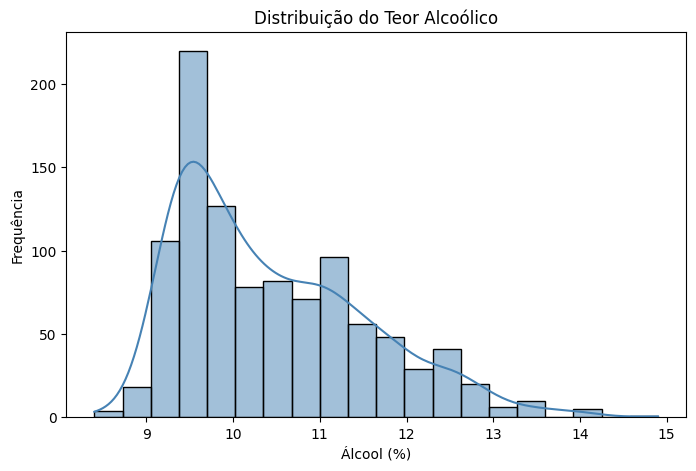

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='alcohol',
    kde=True,
    color='steelblue'
)

plt.title('Distribuição do Teor Alcoólico')
plt.xlabel('Álcool (%)')
plt.ylabel('Frequência')

plt.show()


In [ ]:
df['alcohol'].agg(['mean', 'std'])

,alcohol
mean,10.452456
std,1.095064


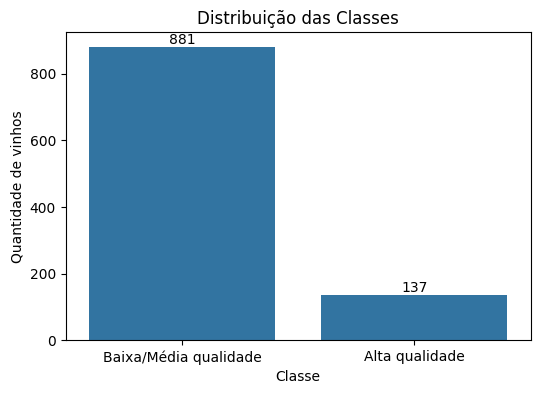

In [ ]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    x='quality_binary',
    data=df
)

plt.title('Distribuição das Classes')
plt.xlabel('Classe')
plt.ylabel('Quantidade de vinhos')
plt.xticks([0, 1], ['Baixa/Média qualidade', 'Alta qualidade'])

# mostra a quantidade em cima de cada barra
for barra in ax.containers:
    ax.bar_label(barra)

plt.show()

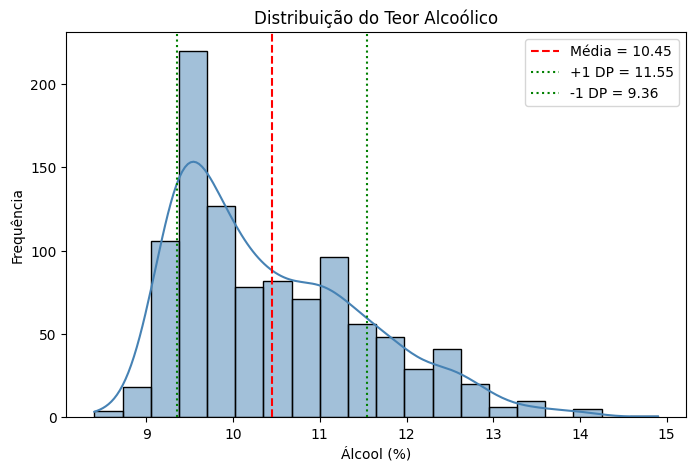

In [ ]:
media = df['alcohol'].mean()
desvio = df['alcohol'].std()

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='alcohol',
    kde=True,
    color='steelblue'
)

plt.axvline(media, color='red', linestyle='--', label=f'Média = {media:.2f}')

plt.axvline(media + desvio, color='green', linestyle=':', label=f'+1 DP = {media + desvio:.2f}')

plt.axvline(media - desvio, color='green', linestyle=':', label=f'-1 DP = {media - desvio:.2f}')

plt.title('Distribuição do Teor Alcoólico')
plt.xlabel('Álcool (%)')
plt.ylabel('Frequência')
plt.legend()
plt.show()

In [ ]:
print("Média", df['alcohol'].mean())
print("Desvio-padrão", df['alcohol'].std())

Média 10.4524557956778
Desvio-padrão 1.0950642991895356


A distribuição do teor alcoólico apresenta um pico de frequência logo acima de 9%, indicando que a maior parte das amostras possui graduação alcoólica relativamente moderada. A distribuição se concentra entre 9% e 11%, com média de 10,45% e desvio-padrão de 1,10, o que mostra que valores muito baixos ou muito elevados são menos frequentes.


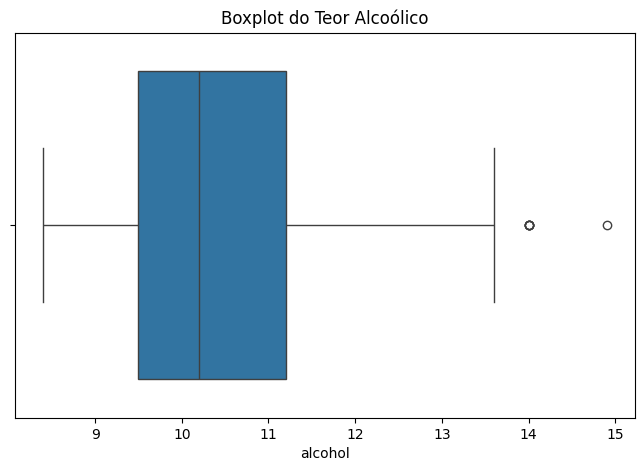

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['alcohol']
)

plt.title('Boxplot do Teor Alcoólico')

plt.show()

# **Presença de outliers**

A análise do boxplot do teor alcoólico identificou a presença de outliers. Como esses valores podem refletir características reais de determinados vinhos e não necessariamente erros de medição, optou-se por mantê-los na base de dados.

**Resumo do que sabemos até aqui sobre o álcool**

*   Pico de frequência logo acima de 9%
*   Média de 10,45%
*   Distribuição concentrada em torno dos valores centrais
*   Presença de poucos outliers
*   Variável aparentemente consistente

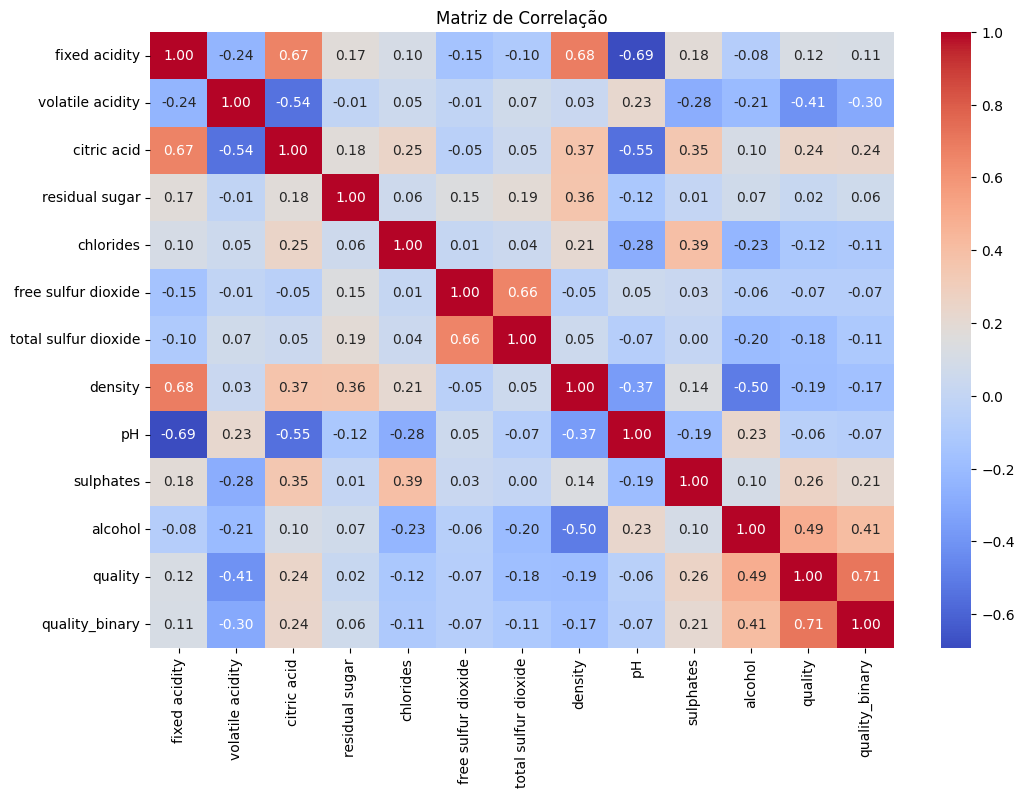

In [ ]:
plt.figure(figsize=(12,8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlação')

plt.show()

# **Maiores Correlações**

quality e quality_binary                   = 0,71

density e fixed acidity                    = 0,68

citric acid e fixed acidity                = 0,67

free sulfur dioxide e total sulfur dioxide = 0,66

# **Menores Correlações**

pH e fixed acidity                      = -0,69

citric acid e pH                        = -0,55

citric acid e volatile acidity          = -0,54

density e alcohol                       = -0,50

# **RESULTADOS DA MATRIZ DE CORRELAÇÃO**

A análise da matriz de correlação revelou relações relevantes entre algumas das variáveis físico-químicas do conjunto de dados. Entre as correlações positivas mais fortes, destacam-se as relações entre densidade e acidez fixa (r = 0,68), entre acidez fixa e ácido cítrico (r = 0,67) e entre dióxido de enxofre livre e dióxido de enxofre total (r = 0,66). Esses resultados indicam que essas variáveis tendem a aumentar juntas nas amostras analisadas.

Entre as correlações negativas, a mais expressiva foi observada entre pH e acidez fixa (r = -0,69), seguida das relações entre ácido cítrico e pH (r = -0,55), ácido cítrico e acidez volátil (r = -0,54) e densidade e teor alcoólico (r = -0,50). Esses resultados sugerem relações inversas entre as características químicas dos vinhos.

A correlação entre a variável original de qualidade e a variável binária criada para a classificação foi de 0,71, resultado esperado, já que uma foi criada a partir da outra.


# **DISCUSSÃO DA MATRIZ DE CORRELAÇÃO**

As correlações identificadas são coerentes com as propriedades físico-químicas dos vinhos. A forte correlação negativa entre pH e acidez fixa (r = -0,69) indica que amostras com maior acidez tendem a apresentar menores valores de pH, comportamento esperado do ponto de vista químico.

A correlação positiva entre acidez fixa e ácido cítrico (r = 0,67) sugere que ambos os componentes contribuem juntos para a composição ácida do vinho. Da mesma forma, a correlação positiva entre dióxido de enxofre livre e dióxido de enxofre total (r = 0,66) era esperada, já que as duas variáveis medem partes do mesmo composto presente na bebida.

Outro resultado relevante foi a correlação negativa entre densidade e teor alcoólico (r = -0,50), indicando que vinhos com maior concentração alcoólica tendem a apresentar menor densidade. Esse comportamento está ligado ao processo de fermentação, em que o açúcar é convertido em álcool, que é menos denso que a água.

Essas correlações ajudam a compreender como os parâmetros químicos interagem entre si e trazem informações importantes para a etapa de modelagem, ao indicar quais variáveis podem influenciar a qualidade do vinho.


# **Quais variáveis influenciam a qualidade do vinho?**

Para responder quais variáveis são mais importantes e quais são irrelevantes, medimos a correlação de cada característica com a nota de qualidade.

In [ ]:
corr = df.corr(numeric_only=True)
corr['quality'].sort_values(ascending=False)


,quality
quality,1.000000
quality_binary,0.713515
alcohol,0.485953
sulphates,0.257519
citric acid,0.241565
fixed acidity,0.115826
residual sugar,0.022718
pH,-0.057592
free sulfur dioxide,-0.071083
chlorides,-0.122214


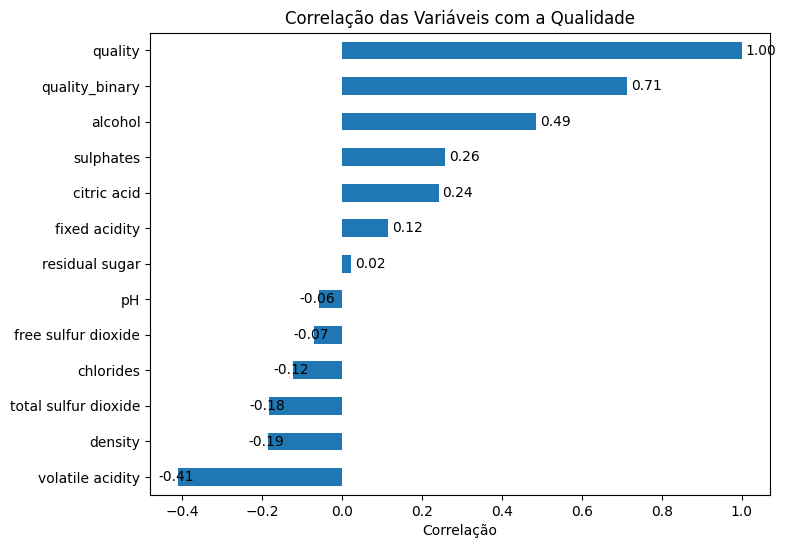

In [ ]:
ax = corr['quality'].sort_values().plot(
    kind='barh',
    figsize=(8, 6)
)

# Adicionar os rótulos de dados
for i, v in enumerate(corr['quality'].sort_values()):
    ax.text(
        v + (0.01 if v >= 0 else -0.05),  # deslocamento horizontal
        i,
        f'{v:.2f}',
        va='center'
    )

plt.title('Correlação das Variáveis com a Qualidade')
plt.xlabel('Correlação')
plt.show()

# RESULTADOS DA CORRELAÇÃO ENTRE AS CARACTERÍSTICAS QUÍMICAS E QUALIDADE DO VINHO

**Variáveis com correlação positiva**

Álcool (≈ 0,49)
É a variável com maior correlação positiva, indicando que valores mais altos tendem a estar associados a vinhos de melhor qualidade.

Sulfatos (≈ 0,26)
Apresentam correlação positiva fraca, mas é a segunda maior entre as variáveis, sugerindo que concentrações maiores podem estar relacionadas a vinhos mais bem avaliados.

Ácido cítrico (≈ 0,24)
Também apresenta correlação positiva, ainda que mais discreta.

Acidez fixa (≈ 0,12)
Correlação positiva fraca, mas presente.

Açúcar residual (≈ 0,02)
Correlação praticamente nula, indicando pouca influência na qualidade.

**Variáveis com correlação negativa**

Acidez volátil (≈ -0,41)
É a variável com maior correlação negativa, indicando que níveis mais altos tendem a estar associados a vinhos de menor qualidade.

Densidade (≈ -0,19)
Correlação negativa fraca.

Dióxido de enxofre total (≈ -0,18)
Correlação negativa fraca.

Cloretos (≈ -0,12)
Correlação negativa leve.

Dióxido de enxofre livre (≈ -0,07)
Correlação negativa muito fraca.

pH (≈ -0,06)
Correlação negativa mínima, indicando que o pH praticamente não diferencia vinhos bons de ruins nesta base.

O gráfico de barras horizontais permite visualizar essas relações de forma clara, destacando o álcool como o principal fator positivo e a acidez volátil como o principal fator negativo.

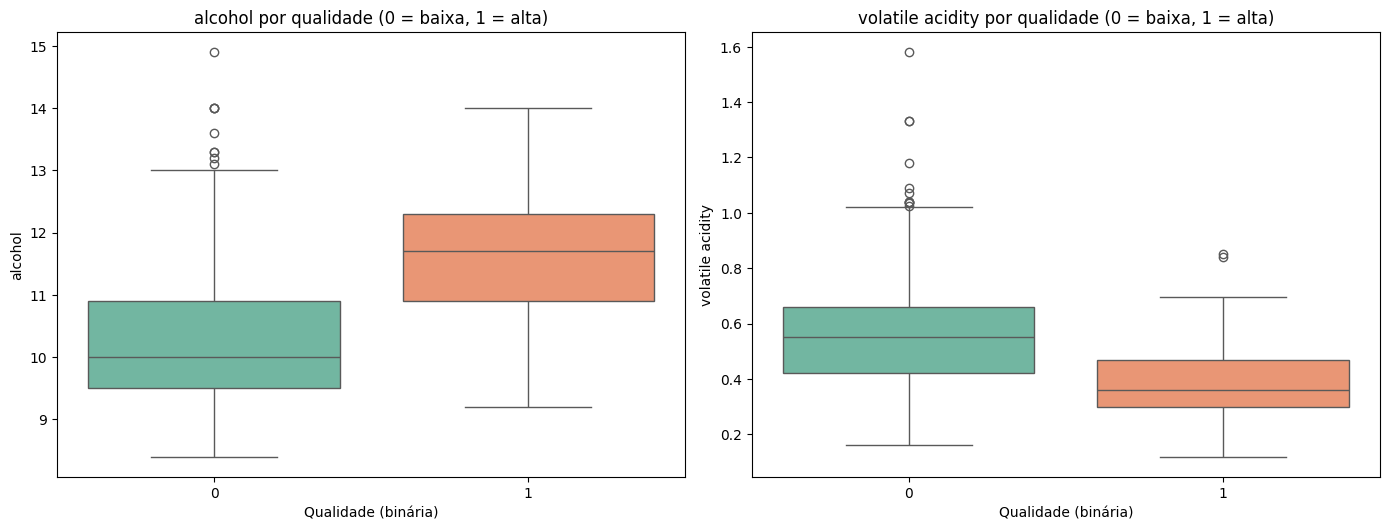

In [ ]:
plt.figure(figsize=(14,10))

variaveis = ['alcohol', 'volatile acidity']

for i, var in enumerate(variaveis, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x='quality_binary', y=var, hue='quality_binary', palette='Set2', legend=False)
    plt.title(f'{var} por qualidade (0 = baixa, 1 = alta)')
    plt.xlabel('Qualidade (binária)')
    plt.ylabel(var)

plt.tight_layout()
plt.show()

# RESULTADO DA COMPARAÇÃO DAS VARIÁVEIS MAIS IMPORTANTES ENTRE VINHOS BONS E RUINS

Os boxplots mostram uma diferença clara entre os dois grupos. Os vinhos de alta qualidade têm, em geral, teor alcoólico mais alto, o que confirma a correlação positiva vista antes. Já a acidez volátil vai no sentido contrário: nos vinhos bons, ela tende a ser mais baixa.

Com isso, álcool e acidez volátil aparecem como as duas variáveis que mais ajudam a separar vinhos de alta qualidade dos demais.


# **Análise da Acidez Volátil**

Analisamos a acidez volátil da mesma forma que fizemos com o teor alcoólico.

In [ ]:
df['volatile acidity'].describe()


,volatile acidity
count,1018.000000
mean,0.533541
std,0.183167
min,0.120000
25%,0.390000
50%,0.520000
75%,0.645000
max,1.580000


In [ ]:
df['volatile acidity'].agg(['mean', 'std'])

,volatile acidity
mean,0.533541
std,0.183167


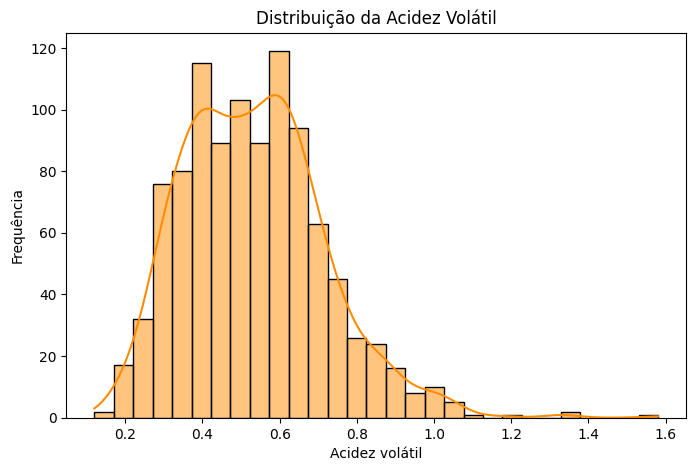

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='volatile acidity',
    kde=True,
    color='darkorange'
)

plt.title('Distribuição da Acidez Volátil')
plt.xlabel('Acidez volátil')
plt.ylabel('Frequência')

plt.show()

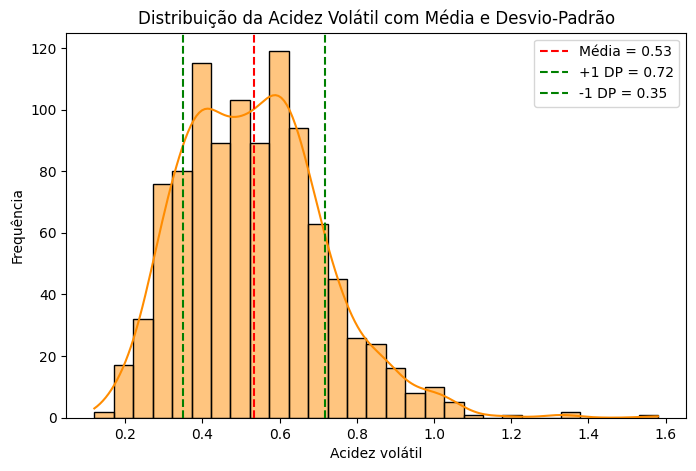

In [ ]:
media_va = df['volatile acidity'].mean()
desvio_va = df['volatile acidity'].std()

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='volatile acidity',
    kde=True,
    color='darkorange'
)

# linha da média
plt.axvline(media_va, color='red', linestyle='--', label=f'Média = {media_va:.2f}')

# linhas de ±1 desvio-padrão
plt.axvline(media_va + desvio_va, color='green', linestyle='--', label=f'+1 DP = {media_va + desvio_va:.2f}')
plt.axvline(media_va - desvio_va, color='green', linestyle='--', label=f'-1 DP = {media_va - desvio_va:.2f}')

plt.title('Distribuição da Acidez Volátil com Média e Desvio-Padrão')
plt.xlabel('Acidez volátil')
plt.ylabel('Frequência')
plt.legend()

plt.show()


# **Boxplot da Acidez Volátil (outliers)**

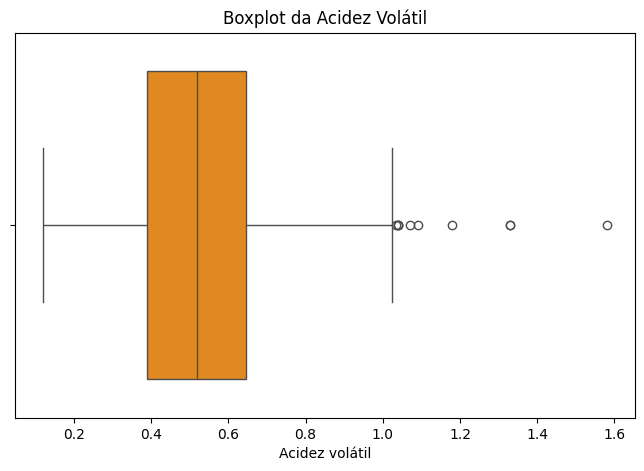

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['volatile acidity'],
    color='darkorange'
)

plt.title('Boxplot da Acidez Volátil')
plt.xlabel('Acidez volátil')

plt.show()

# **Distribuição da acidez volátil por classe (bons vs ruins)**

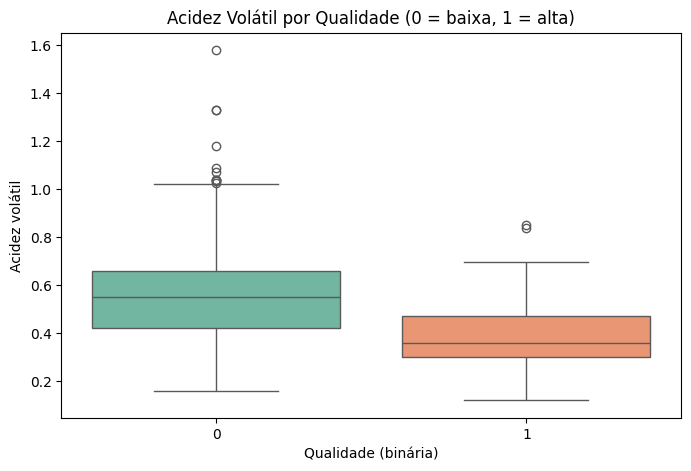

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='quality_binary',
    y='volatile acidity',
    hue='quality_binary',
    palette='Set2',
    legend=False
)

plt.title('Acidez Volátil por Qualidade (0 = baixa, 1 = alta)')
plt.xlabel('Qualidade (binária)')
plt.ylabel('Acidez volátil')

plt.show()

# Histogramas separados por classe

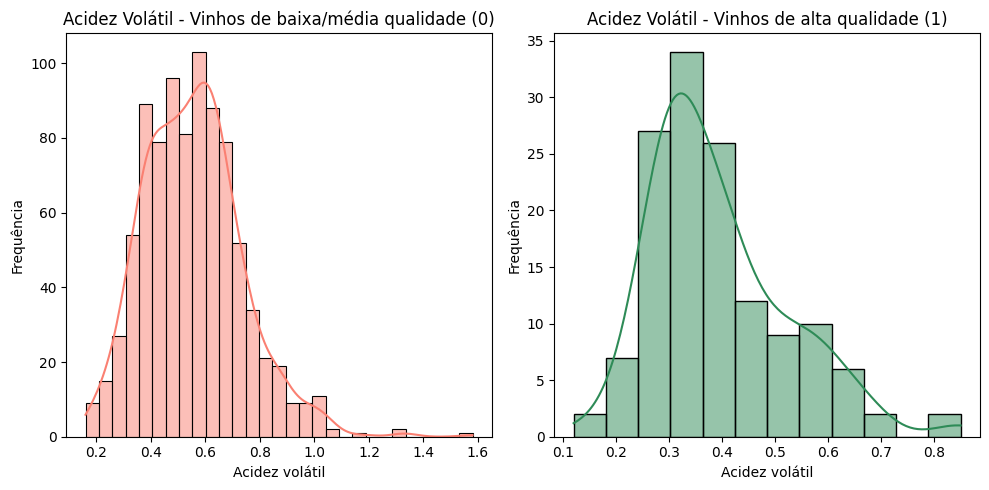

In [ ]:
plt.figure(figsize=(10,5))

# classe 0 - baixa/média qualidade
plt.subplot(1, 2, 1)
sns.histplot(
    data=df[df['quality_binary'] == 0],
    x='volatile acidity',
    kde=True,
    color='salmon'
)
plt.title('Acidez Volátil - Vinhos de baixa/média qualidade (0)')
plt.xlabel('Acidez volátil')
plt.ylabel('Frequência')

# classe 1 - alta qualidade
plt.subplot(1, 2, 2)
sns.histplot(
    data=df[df['quality_binary'] == 1],
    x='volatile acidity',
    kde=True,
    color='seagreen'
)
plt.title('Acidez Volátil - Vinhos de alta qualidade (1)')
plt.xlabel('Acidez volátil')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

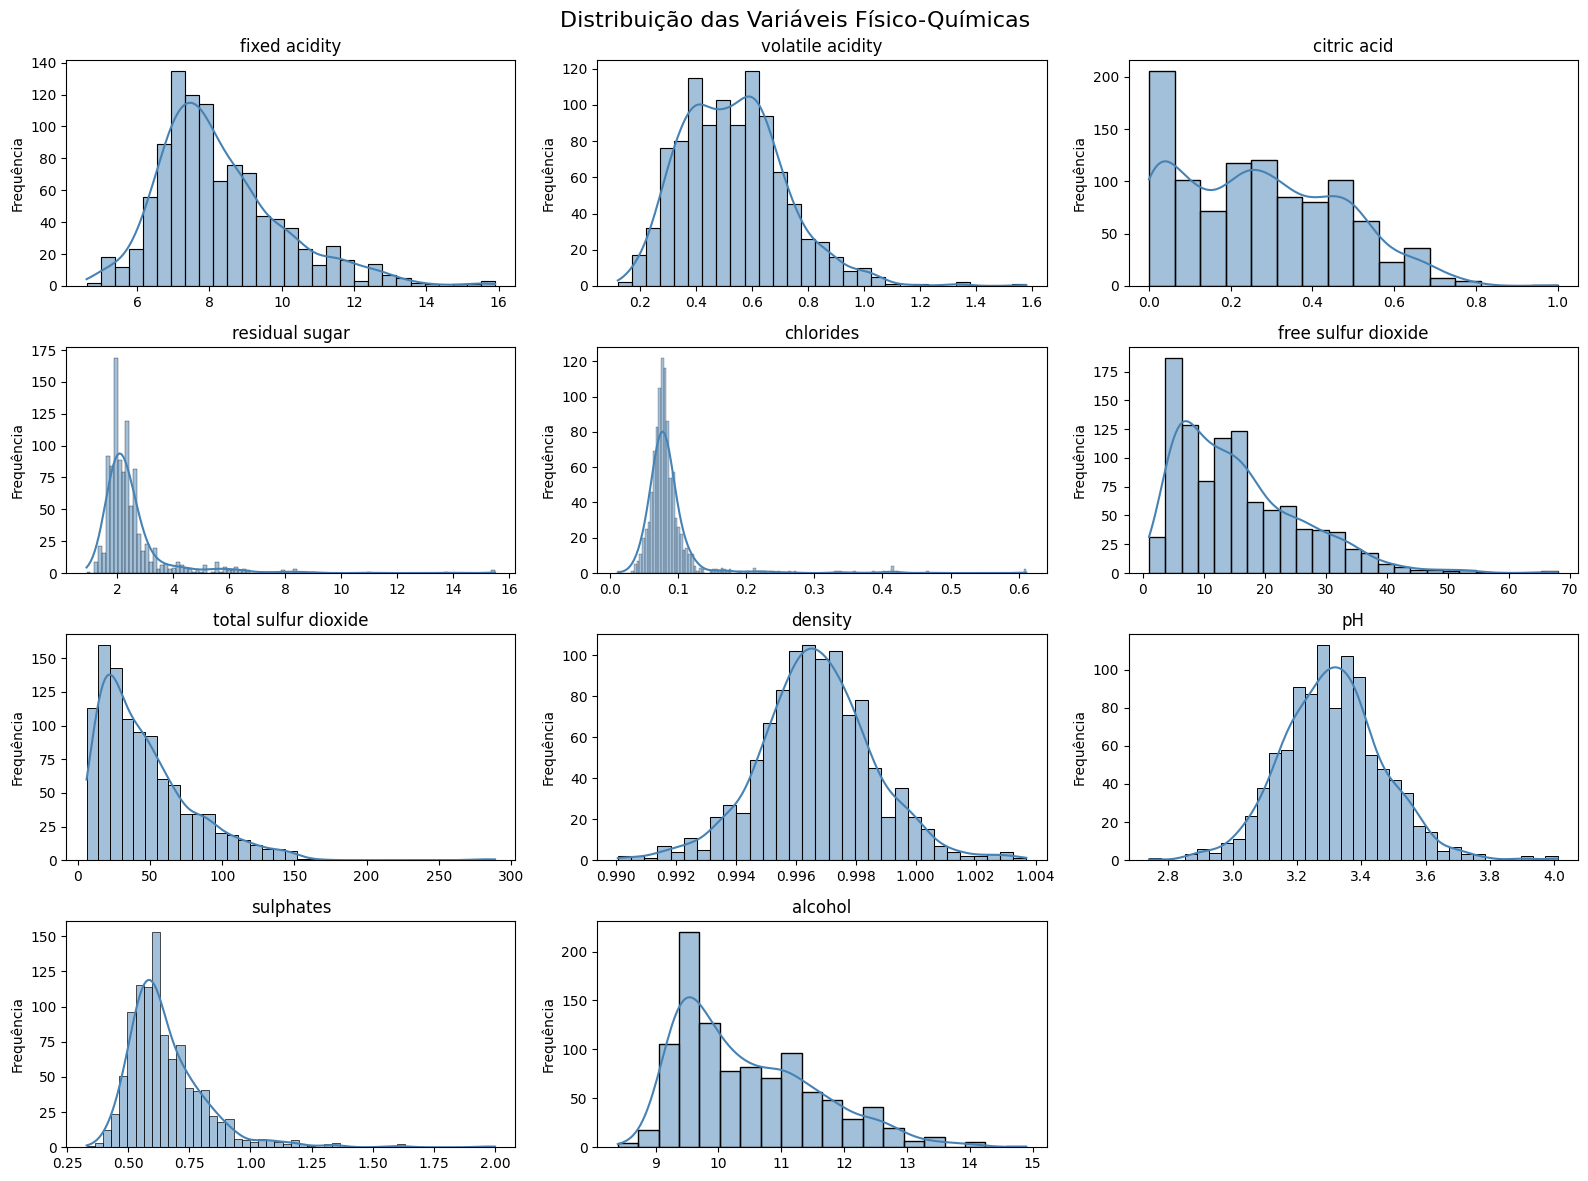

In [ ]:
variaveis = df.drop(columns=['quality', 'quality_binary']).columns

plt.figure(figsize=(16, 12))

for i, var in enumerate(variaveis, 1):
    plt.subplot(4, 3, i)
    sns.histplot(data=df, x=var, kde=True, color='steelblue')
    plt.title(var)
    plt.xlabel('')
    plt.ylabel('Frequência')

plt.suptitle('Distribuição das Variáveis Físico-Químicas', fontsize=16)
plt.tight_layout()
plt.show()

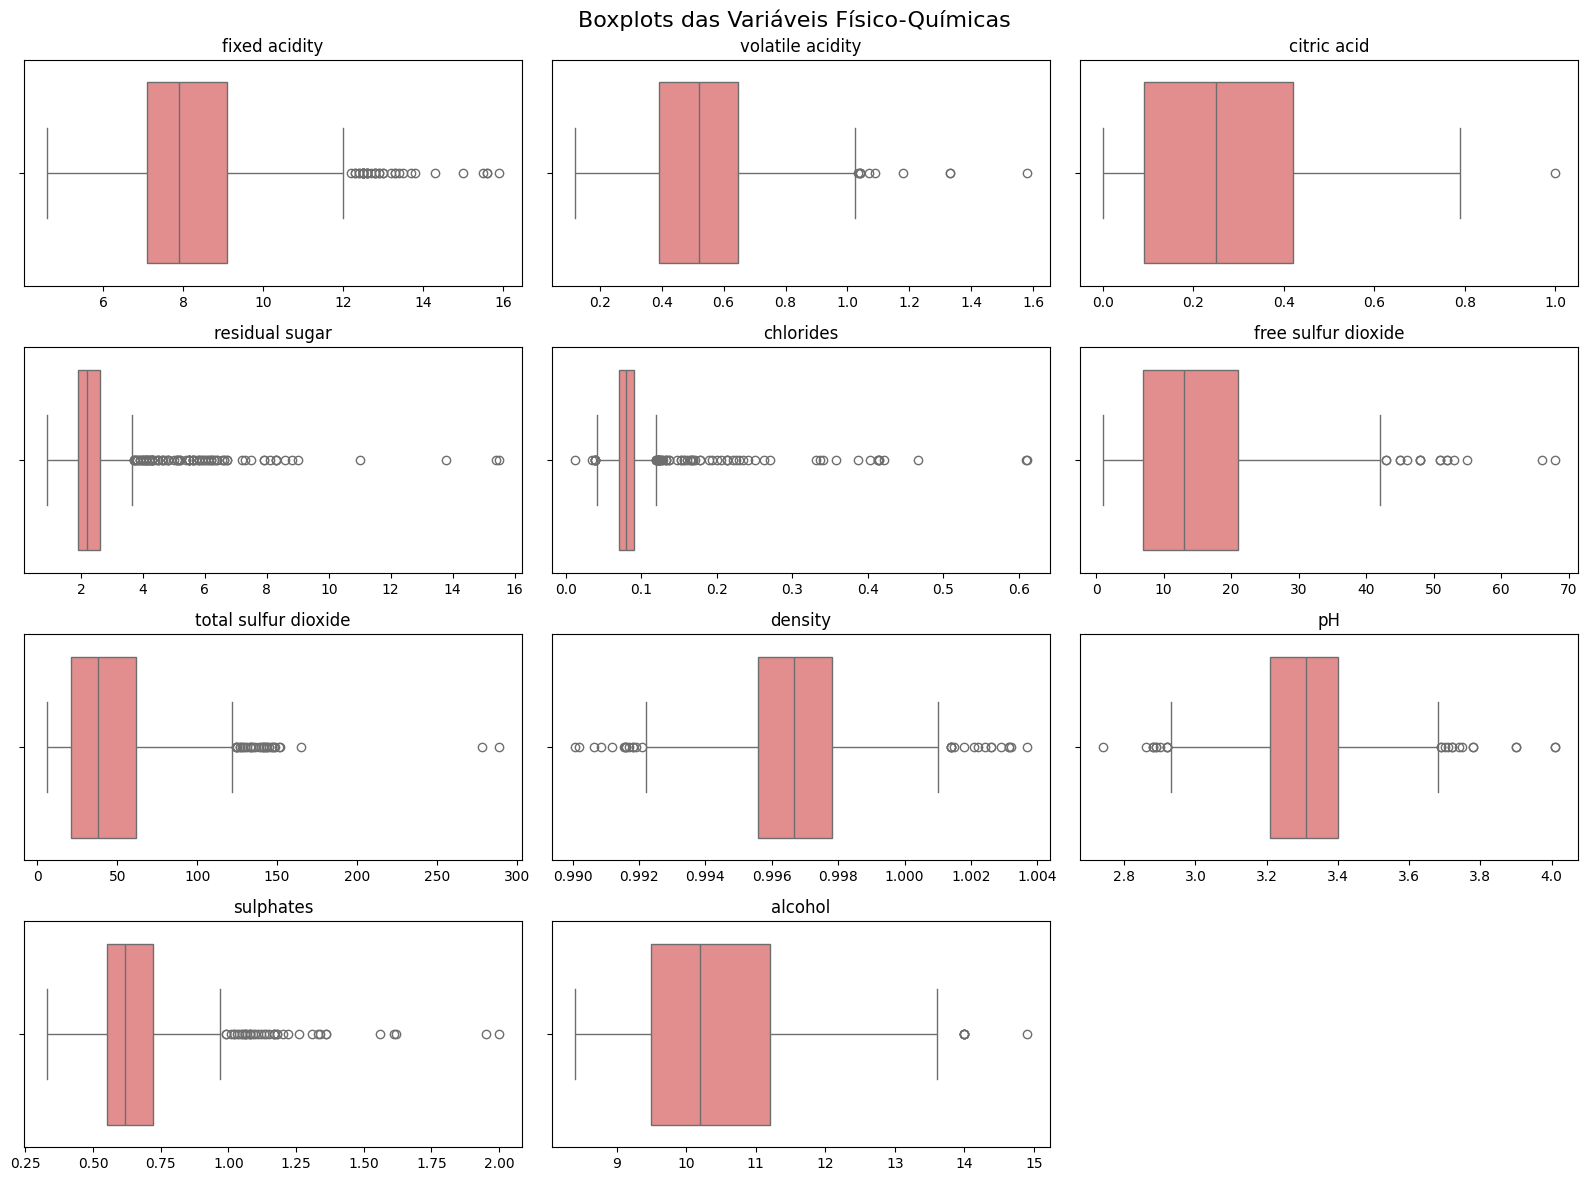

In [ ]:
plt.figure(figsize=(16, 12))

for i, var in enumerate(variaveis, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[var], color='lightcoral')
    plt.title(var)
    plt.xlabel('')

plt.suptitle('Boxplots das Variáveis Físico-Químicas', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
outliers = {}

for var in variaveis:
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1
    outliers[var] = ((df[var] < q1 - 1.5 * iqr) | (df[var] > q3 + 1.5 * iqr)).sum()

pd.Series(outliers).sort_values(ascending=False)

,0
residual sugar,95
chlorides,71
sulphates,41
fixed acidity,37
total sulfur dioxide,33
density,30
pH,24
free sulfur dioxide,16
volatile acidity,10
alcohol,6


# **Distribuição das variáveis e outliers**

Olhando todas as variáveis juntas, dá para separar dois comportamentos.

Densidade e pH têm distribuições quase simétricas, com os valores bem concentrados em torno da média. Acidez volátil, ácido cítrico e álcool também são relativamente bem comportados, com poucos valores fora do padrão.

Já açúcar residual, cloretos e sulfatos são bem assimétricos: a maioria dos vinhos tem valores baixos, e alguns poucos têm valores muito acima do resto. É por isso que essas três variáveis concentram a maior parte dos outliers (95 em açúcar residual, 71 em cloretos e 41 em sulfatos).

Decidimos manter os outliers. Eles parecem representar vinhos com características diferentes, e não erros de medição. Além disso, removê-los reduziria ainda mais a base, que já é pequena, principalmente na classe de alta qualidade. Na etapa de modelagem, a padronização das variáveis e o uso de modelos baseados em árvores ajudam a diminuir o impacto desses valores extremos.

# **Etapa 3: Pré-processamento**

Antes de treinar os modelos, precisamos preparar os dados. Nesta etapa separamos as características do vinho da resposta que queremos prever, dividimos a base em treino e teste e colocamos todas as variáveis na mesma escala.

In [ ]:
# X: características físico-químicas do vinho
# y: o que queremos prever (1 = alta qualidade, 0 = baixa/média)
X = df.drop(columns=['quality', 'quality_binary'])
y = df['quality_binary']

print('Formato de X:', X.shape)
print('Formato de y:', y.shape)

Formato de X: (1018, 11)
Formato de y: (1018,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)
print('\nClasses no treino:\n', y_train.value_counts())
print('\nClasses no teste:\n', y_test.value_counts())

Treino: (814, 11)
Teste: (204, 11)

Classes no treino:
 quality_binary
0    704
1    110
Name: count, dtype: int64

Classes no teste:
 quality_binary
0    177
1     27
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# O scaler aprende a média e o desvio só com o treino e aplica a mesma regra no teste
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Padronização concluída')

Padronização concluída


**O que foi feito no pré-processamento**

Dados faltantes: não foi preciso nenhum tratamento, porque a base não tem valores ausentes.

Divisão treino e teste: separamos 80% dos vinhos para treinar o modelo e 20% para testar. Usamos a opção stratify para manter a mesma proporção de vinhos bons e ruins nos dois grupos. Sem isso, com tão poucos vinhos de alta qualidade, o teste poderia acabar com pouquíssimos exemplos dessa classe.

Padronização: as variáveis estão em escalas muito diferentes. A densidade, por exemplo, fica perto de 1, enquanto o dióxido de enxofre total passa de 100. Com a padronização, todas passam a ter média 0 e desvio-padrão 1, o que evita que uma variável pese mais no modelo só por ter números maiores. A média e o desvio foram calculados apenas com os dados de treino, para que o modelo não tenha nenhuma informação do teste antes da avaliação.

Novas variáveis: optamos por não criar novas variáveis neste momento. As variáveis originais já têm significado químico claro, e a análise exploratória não indicou uma combinação que trouxesse ganho evidente.

# **Etapa 4: Desenvolvimento dos Modelos**

Treinamos dois modelos de classificação com abordagens diferentes. A Regressão Logística é um modelo mais simples, que encontra uma relação direta entre as características do vinho e a chance de ele ser de alta qualidade. A Random Forest combina centenas de árvores de decisão e consegue captar relações mais complexas entre as variáveis.

Como a base tem poucos vinhos de alta qualidade, usamos nos dois modelos a opção class_weight='balanced'. Ela faz o modelo dar mais peso aos erros na classe rara, para que ele não aprenda apenas a dizer "baixa qualidade" para tudo.


In [ ]:
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# A Regressão Logística usa os dados padronizados
modelo_lr.fit(X_train_scaled, y_train)
y_pred_lr = modelo_lr.predict(X_test_scaled)

print('Regressão Logística treinada')

Regressão Logística treinada


In [ ]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

# A Random Forest não precisa de padronização, então usamos os dados originais
modelo_rf.fit(X_train, y_train)
y_pred_rf = modelo_rf.predict(X_test)

print('Random Forest treinada')

Random Forest treinada


**Por que dados diferentes em cada modelo?**

A Regressão Logística é sensível à escala das variáveis, por isso foi treinada com os dados padronizados. A Random Forest toma decisões comparando valores dentro de cada variável, então a escala não interfere no resultado, e ela foi treinada com os dados originais. Isso também facilita a interpretação das variáveis mais importantes na etapa 6.

# **Etapa 5: Avaliação dos Modelos**

Como a base é desbalanceada, a acurácia sozinha não é suficiente para avaliar os modelos. Por isso, olhamos também para:

*   Precisão: dos vinhos que o modelo apontou como de alta qualidade, quantos realmente eram
*   Recall: dos vinhos de alta qualidade que existiam no teste, quantos o modelo conseguiu encontrar
*   F1-score: equilíbrio entre precisão e recall
*   ROC-AUC: capacidade do modelo de dar notas mais altas para vinhos bons do que para vinhos ruins, independentemente do ponto de corte

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

prob_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

resultados = pd.DataFrame({
    'Regressão Logística': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr),
        roc_auc_score(y_test, prob_lr)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, prob_rf)
    ]
}, index=['Acurácia', 'Precisão', 'Recall', 'F1-score', 'ROC-AUC'])

resultados.round(3)

,Regressão Logística,Random Forest
Acurácia,0.784,0.907
Precisão,0.356,0.900
Recall,0.778,0.333
F1-score,0.488,0.486
ROC-AUC,0.882,0.932


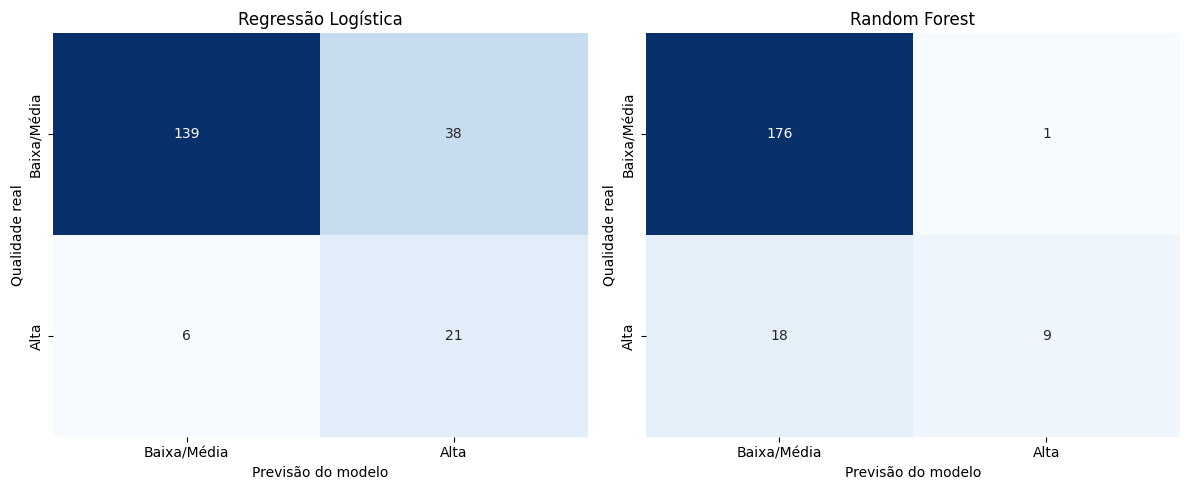

In [ ]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rotulos = ['Baixa/Média', 'Alta']

for ax, pred, titulo in zip(axes, [y_pred_lr, y_pred_rf], ['Regressão Logística', 'Random Forest']):
    matriz = confusion_matrix(y_test, pred)
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=rotulos, yticklabels=rotulos, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel('Previsão do modelo')
    ax.set_ylabel('Qualidade real')

plt.tight_layout()
plt.show()

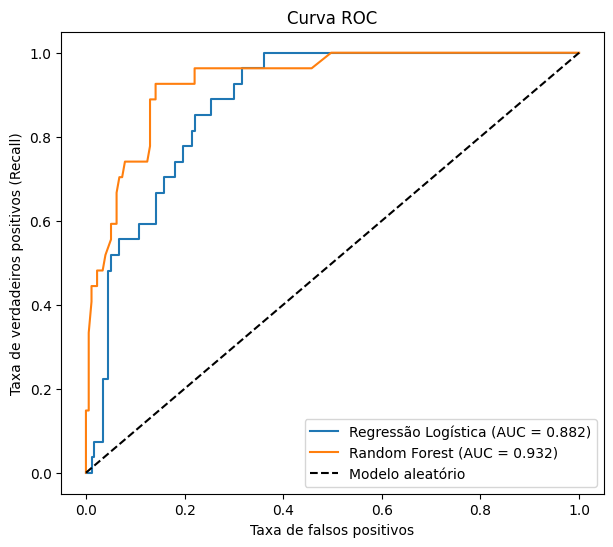

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for prob, nome in [(prob_lr, 'Regressão Logística'), (prob_rf, 'Random Forest')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Modelo aleatório')
plt.title('Curva ROC')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos (Recall)')
plt.legend()
plt.show()

**Comparação dos resultados**

| Métrica | Regressão Logística | Random Forest |
|---|---|---|
| Acurácia | 0,784 | 0,907 |
| Precisão | 0,356 | 0,900 |
| Recall | 0,778 | 0,333 |
| F1-score | 0,488 | 0,486 |
| ROC-AUC | 0,882 | 0,932 |

Os dois modelos têm F1-score praticamente igual, mas se comportam de formas bem diferentes.

A Regressão Logística encontrou 21 dos 27 vinhos de alta qualidade do teste (recall de 78%). Em compensação, apontou como bons 38 vinhos que não eram, então só cerca de um em cada três vinhos que ela classificou como alta qualidade estava certo.

A Random Forest foi muito mais cuidadosa: dos 10 vinhos que ela apontou como bons, 9 realmente eram (precisão de 90%). Mas ela deixou passar 18 dos 27 vinhos de alta qualidade, encontrando só um em cada três.

A acurácia da Random Forest (90,7%) parece bem melhor, mas vale lembrar que um modelo que dissesse "baixa qualidade" para todos os vinhos já teria 86,8% de acurácia neste teste. Por isso essa métrica, sozinha, não decide a comparação.

A Random Forest teve o maior ROC-AUC (0,932), o que mostra que ela separa melhor os vinhos bons dos ruins quando olhamos para as probabilidades. O recall baixo vem do ponto de corte padrão de 50%: com tão poucos vinhos bons, o modelo raramente chega a essa confiança.

A escolha entre os dois depende do objetivo do produtor. Se a prioridade é não deixar passar nenhum vinho com potencial, a Regressão Logística é mais indicada. Se a prioridade é ter segurança ao classificar um vinho como premium, por exemplo para precificação ou rotulagem, a Random Forest é a melhor opção.

# **Etapa 5.1: Validação cruzada**

Com apenas 27 vinhos de alta qualidade no conjunto de teste, os resultados podem mudar bastante dependendo de quais vinhos caíram no teste. Para confirmar que as métricas não são fruto de uma divisão favorável, usamos validação cruzada com 5 partes: a base é dividida em 5 grupos, e cada modelo é treinado e testado 5 vezes, cada vez com um grupo diferente como teste. Incluímos também um terceiro modelo, o Gradient Boosting, para enriquecer a comparação.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_cv = {
    'Regressão Logística': make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
    ),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

metricas = {'accuracy': 'Acurácia', 'precision': 'Precisão', 'recall': 'Recall', 'f1': 'F1-score', 'roc_auc': 'ROC-AUC'}

resultados_cv = {}
for nome, modelo in modelos_cv.items():
    r = cross_validate(modelo, X, y, cv=cv, scoring=list(metricas))
    resultados_cv[nome] = {rotulo: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m, rotulo in metricas.items()}

pd.DataFrame(resultados_cv).T

,Acurácia,Precisão,Recall,F1-score,ROC-AUC
Regressão Logística,0.798 ± 0.029,0.386 ± 0.041,0.811 ± 0.046,0.521 ± 0.037,0.878 ± 0.022
Random Forest,0.894 ± 0.015,0.731 ± 0.074,0.352 ± 0.159,0.452 ± 0.140,0.883 ± 0.030
Gradient Boosting,0.882 ± 0.014,0.586 ± 0.053,0.395 ± 0.125,0.466 ± 0.097,0.870 ± 0.026


**Resultado da validação cruzada** (média ± desvio-padrão das 5 rodadas)

| Modelo | Acurácia | Precisão | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Regressão Logística | 0,798 ± 0,029 | 0,386 ± 0,041 | 0,811 ± 0,046 | 0,521 ± 0,037 | 0,878 ± 0,022 |
| Random Forest | 0,894 ± 0,015 | 0,731 ± 0,074 | 0,352 ± 0,159 | 0,452 ± 0,140 | 0,883 ± 0,030 |
| Gradient Boosting | 0,882 ± 0,014 | 0,586 ± 0,053 | 0,395 ± 0,125 | 0,466 ± 0,097 | 0,870 ± 0,026 |

A validação cruzada confirma o padrão visto no teste: a Regressão Logística encontra mais vinhos bons (recall de 81%), enquanto a Random Forest é mais precisa, mas deixa passar a maioria deles.

Ela também traz duas informações novas. A primeira é que, considerando as 5 rodadas, a capacidade de separação dos modelos é muito parecida (ROC-AUC entre 0,870 e 0,883). O ROC-AUC de 0,932 da Random Forest no teste foi, em parte, favorecido pela divisão escolhida. A segunda é que o recall da Random Forest varia muito entre as rodadas (± 0,159), o que mostra que, com o ponto de corte padrão de 50%, ela é instável na hora de encontrar os vinhos bons.

O Gradient Boosting ficou entre os dois e não trouxe ganho em relação aos modelos já testados.

# **Etapa 5.2: Ajuste do ponto de corte**

Por padrão, o modelo só classifica um vinho como de alta qualidade quando a probabilidade calculada passa de 50%. Com tão poucos vinhos bons na base, esse corte é exigente demais, e por isso a Random Forest deixava passar tantos vinhos de qualidade.

Testamos pontos de corte entre 10% e 60% e escolhemos o que gerou o melhor F1-score. Para que o conjunto de teste continue sendo uma avaliação justa, essa escolha foi feita apenas com os dados de treino, usando validação cruzada.

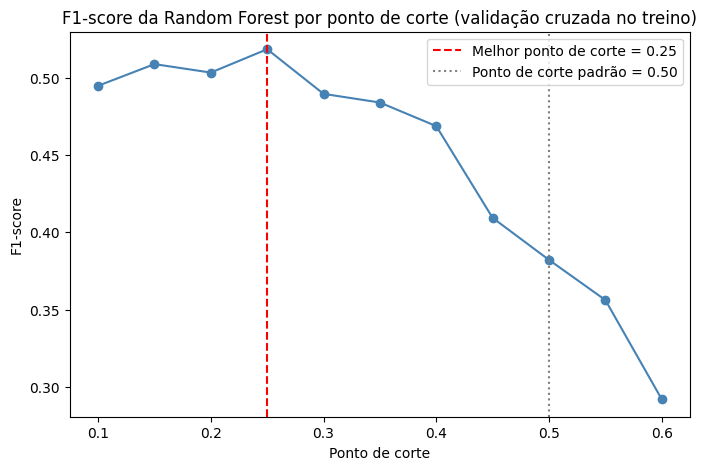

Melhor ponto de corte: 0.25


In [ ]:
from sklearn.model_selection import cross_val_predict
import numpy as np

prob_treino_cv = cross_val_predict(
    RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

limiares = np.round(np.arange(0.10, 0.61, 0.05), 2)
f1_por_limiar = [f1_score(y_train, (prob_treino_cv >= t).astype(int)) for t in limiares]

melhor_limiar = limiares[int(np.argmax(f1_por_limiar))]

plt.figure(figsize=(8, 5))
plt.plot(limiares, f1_por_limiar, marker='o', color='steelblue')
plt.axvline(melhor_limiar, color='red', linestyle='--', label=f'Melhor ponto de corte = {melhor_limiar:.2f}')
plt.axvline(0.5, color='gray', linestyle=':', label='Ponto de corte padrão = 0.50')
plt.title('F1-score da Random Forest por ponto de corte (validação cruzada no treino)')
plt.xlabel('Ponto de corte')
plt.ylabel('F1-score')
plt.legend()
plt.show()

print('Melhor ponto de corte:', melhor_limiar)

In [ ]:
y_pred_rf_ajustado = (prob_rf >= melhor_limiar).astype(int)

comparacao_corte = pd.DataFrame({
    'Random Forest (corte 0.50)': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ],
    f'Random Forest (corte {melhor_limiar:.2f})': [
        accuracy_score(y_test, y_pred_rf_ajustado),
        precision_score(y_test, y_pred_rf_ajustado),
        recall_score(y_test, y_pred_rf_ajustado),
        f1_score(y_test, y_pred_rf_ajustado)
    ]
}, index=['Acurácia', 'Precisão', 'Recall', 'F1-score'])

comparacao_corte.round(3)

,Random Forest (corte 0.50),Random Forest (corte 0.25)
Acurácia,0.907,0.887
Precisão,0.900,0.556
Recall,0.333,0.741
F1-score,0.486,0.635


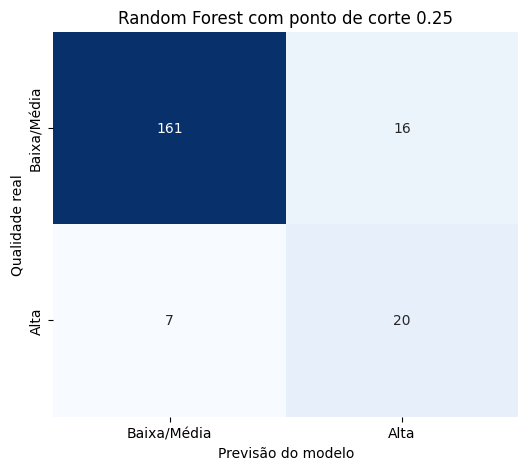

In [ ]:
matriz = confusion_matrix(y_test, y_pred_rf_ajustado)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Baixa/Média', 'Alta'], yticklabels=['Baixa/Média', 'Alta'])
plt.title(f'Random Forest com ponto de corte {melhor_limiar:.2f}')
plt.xlabel('Previsão do modelo')
plt.ylabel('Qualidade real')
plt.show()

**Resultado do ajuste do ponto de corte**

| Métrica | Corte 0,50 | Corte 0,25 |
|---|---|---|
| Acurácia | 0,907 | 0,887 |
| Precisão | 0,900 | 0,556 |
| Recall | 0,333 | 0,741 |
| F1-score | 0,486 | 0,635 |

Com o ponto de corte em 25%, a Random Forest passou a encontrar 20 dos 27 vinhos de alta qualidade do teste, contra apenas 9 antes. Em troca, passou a apontar como bons 16 vinhos que não eram, e a precisão caiu de 90% para cerca de 56%. Na prática, mais da metade dos vinhos que ela indica como alta qualidade realmente são.

O F1-score subiu de 0,486 para 0,635, o melhor resultado obtido no conjunto de teste. Isso mostra que o ponto de corte é uma decisão de negócio, e não apenas técnica: o produtor pode escolher entre um modelo mais rigoroso, que quase não erra quando aponta um vinho bom, e um modelo mais abrangente, que encontra a maioria deles.

# **Etapa 6: Interpretação dos Resultados**

Depois de avaliar os modelos, olhamos para dentro deles para entender quais características mais pesaram na hora de separar vinhos de alta qualidade dos demais.

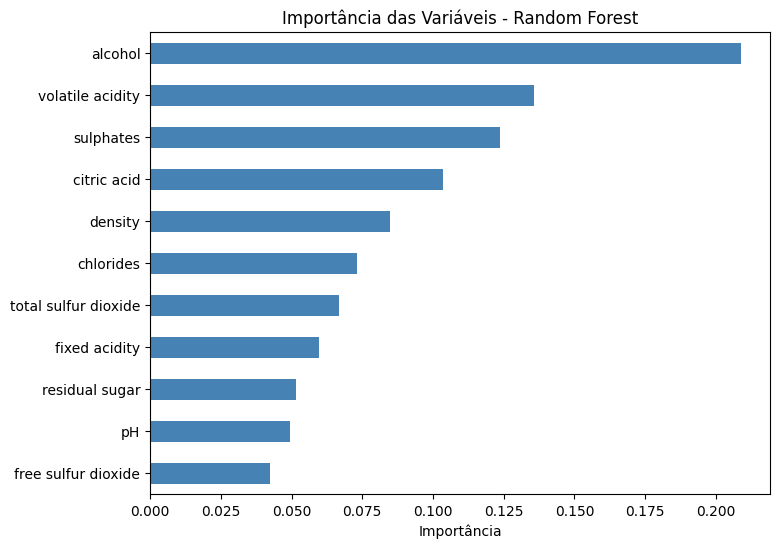

,0
alcohol,0.209
volatile acidity,0.136
sulphates,0.124
citric acid,0.104
density,0.085
chlorides,0.073
total sulfur dioxide,0.067
fixed acidity,0.060
residual sugar,0.052
pH,0.050


In [ ]:
importancia = pd.Series(
    modelo_rf.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(8, 6))
importancia.plot(kind='barh', color='steelblue')
plt.title('Importância das Variáveis - Random Forest')
plt.xlabel('Importância')
plt.show()

importancia.sort_values(ascending=False).round(3)

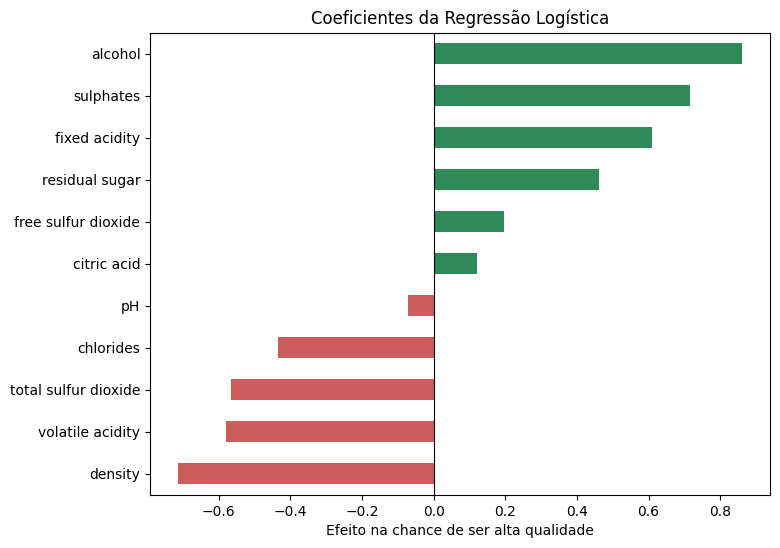

,0
density,-0.71
volatile acidity,-0.58
total sulfur dioxide,-0.57
chlorides,-0.43
pH,-0.07
citric acid,0.12
free sulfur dioxide,0.20
residual sugar,0.46
fixed acidity,0.61
sulphates,0.71


In [ ]:
coeficientes = pd.Series(
    modelo_lr.coef_[0],
    index=X.columns
).sort_values()

cores = ['indianred' if c < 0 else 'seagreen' for c in coeficientes]

plt.figure(figsize=(8, 6))
coeficientes.plot(kind='barh', color=cores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes da Regressão Logística')
plt.xlabel('Efeito na chance de ser alta qualidade')
plt.show()

coeficientes.round(2)

**Quais variáveis mais influenciam a qualidade?**

Os dois modelos chegaram a conclusões parecidas, o que dá mais segurança aos resultados.

O teor alcoólico é a característica mais importante nos dois modelos. Na Random Forest, ele responde por cerca de 21% da importância total, e na Regressão Logística tem o maior efeito positivo. Vinhos com mais álcool têm mais chance de serem de alta qualidade.

A acidez volátil aparece logo em seguida na Random Forest, com efeito negativo nos dois modelos. Ela está ligada ao aroma de vinagre, e níveis mais altos reduzem a chance de o vinho ser bem avaliado.

Os sulfatos são a terceira variável mais relevante, com efeito positivo. Eles ajudam na conservação do vinho e, nesta base, aparecem mais nos vinhos mais bem avaliados.

Na Regressão Logística, a densidade aparece com o maior efeito negativo. Isso acontece em parte porque densidade e álcool andam juntas (vinhos com mais álcool são menos densos), e o modelo acaba dividindo o efeito entre as duas. O dióxido de enxofre total também tem efeito negativo. Já pH e dióxido de enxofre livre estão entre as variáveis menos importantes nos dois modelos, o que confirma o que a análise exploratória já mostrava.

Esses resultados batem com a análise de correlação feita na etapa 2: álcool e acidez volátil eram, desde o início, as variáveis mais associadas à qualidade.

**Implicações para a produção**

Controlar a acidez volátil durante a fermentação e o armazenamento parece ser um dos pontos mais importantes para evitar vinhos de baixa qualidade. Isso envolve higiene, controle de temperatura e cuidado com a exposição ao oxigênio.

O teor alcoólico, que depende principalmente do açúcar da uva no momento da colheita, também se mostrou decisivo. Acompanhar o ponto de maturação pode ajudar a chegar a vinhos mais bem avaliados.

O nível de sulfatos é outro ponto de atenção, por estar associado a vinhos de melhor qualidade nesta base.

Vale lembrar que essas são associações encontradas nos dados, e não provas de causa e efeito. Elas indicam onde o produtor pode concentrar testes e ajustes, mas a decisão final continua dependendo do conhecimento técnico de enólogos. O modelo funciona como uma ferramenta de apoio: pode, por exemplo, sinalizar lotes promissores ou com risco de baixa qualidade antes da avaliação sensorial.

# **Conclusão**

Os modelos conseguiram separar vinhos de alta qualidade dos demais com bom desempenho. A validação cruzada mostrou que a capacidade de separação da Regressão Logística, da Random Forest e do Gradient Boosting é parecida (ROC-AUC entre 0,870 e 0,883), e que a principal diferença entre eles está no equilíbrio entre encontrar vinhos bons e evitar alarmes falsos.

O melhor resultado veio da Random Forest com o ponto de corte ajustado para 25%: ela passou a encontrar 20 dos 27 vinhos de alta qualidade do teste, com o maior F1-score obtido no conjunto de teste (0,635). A escolha do ponto de corte pode ser feita pelo produtor de acordo com o objetivo, priorizando segurança ou abrangência.

As análises, desde a exploração dos dados até os modelos, apontam para as mesmas características: teor alcoólico mais alto e acidez volátil mais baixa são os sinais mais fortes de um vinho bem avaliado, seguidos pelos sulfatos.

Como próximos passos, seria possível ajustar os hiperparâmetros dos modelos e validar os resultados com uma base maior, que inclua mais vinhos de alta qualidade.